# 04 · Job-Shop Scheduling

Where interval reasoning shines. Each job is a chain of operations that must run in order; each operation needs a machine for a fixed time; a machine runs one operation at a time. We model operations as **interval variables** and add one **no-overlap** constraint per machine, then minimise the makespan (total completion time).

In [1]:
import sys
from pathlib import Path

# Make `src` importable whether the notebook runs from repo root or notebooks/.
ROOT = Path.cwd()
while not (ROOT / "pyproject.toml").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

%matplotlib inline
import matplotlib.pyplot as plt

from src.persistence import save_figure, save_json

print("figures ->", save_figure.__module__, "| ready")

figures -> src.persistence | ready


In [2]:
from src.datasets import instances
from src.evaluation.correctness import verify_job_shop
from src.evaluation.scaling import job_shop_scaling
from src.models.job_shop import solve_job_shop
from src.visualisation import gantt_chart

problem = instances.small_job_shop()
save_json("04_job_shop_problem", {
    "jobs": [[list(op) for op in job] for job in problem.jobs],
    "num_machines": problem.num_machines,
})
problem.jobs

(((0, 3), (1, 2), (2, 2)), ((0, 2), (2, 1), (1, 4)), ((1, 4), (2, 3)))

## Solve and verify against the known optimum (makespan = 11)

In [3]:
result = solve_job_shop(problem, time_limit=10.0)
print(result.stats.summary(), "| makespan:", result.makespan)
assert result.starts is not None
print("known optimum:", instances.SMALL_JOB_SHOP_OPTIMUM)
print("optimal:", result.stats.is_optimal, "| schedule valid:",
      verify_job_shop(problem, result.starts, result.makespan))
save_json("04_job_shop_schedule", {"starts": result.starts, "makespan": result.makespan})

status=OPTIMAL time=0.008s objective=11 bound=11 branches=13 | makespan: 11
known optimum: 11
optimal: True | schedule valid: True


PosixPath('/workspaces/constraint_programming_101/outputs/data/04_job_shop_schedule.json')

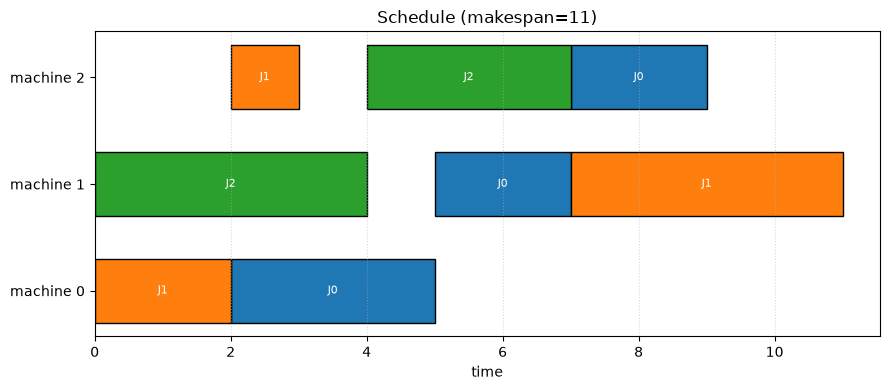

In [4]:
fig = gantt_chart(problem, result.starts, title=f"Schedule (makespan={result.makespan})")
save_figure("04_job_shop_gantt", fig)
plt.show()

## Solve time vs size
Not a benchmark of scale — the point is the paradigm — but a bounded look at how CP-SAT solve time grows as the instance does. Every solve is capped at 5 seconds.

In [5]:
sizes = [3, 5, 8, 12]
points = job_shop_scaling(sizes, time_limit=5.0)
save_json("04_job_shop_scaling", [
    {"size": p.size, "status": p.status, "wall_time": p.wall_time, "makespan": p.makespan}
    for p in points
])
for p in points:
    print(f"{p.size:3} jobs -> {p.status:9} {p.wall_time:6.3f}s  makespan={p.makespan}")

  3 jobs -> OPTIMAL    0.004s  makespan=17
  5 jobs -> OPTIMAL    0.005s  makespan=27
  8 jobs -> OPTIMAL    0.009s  makespan=39
 12 jobs -> OPTIMAL    0.031s  makespan=58


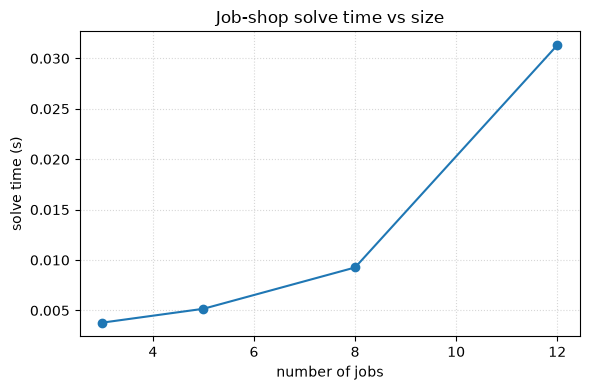

In [6]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot([p.size for p in points], [p.wall_time for p in points], marker="o")
ax.set_xlabel("number of jobs")
ax.set_ylabel("solve time (s)")
ax.set_title("Job-shop solve time vs size")
ax.grid(True, linestyle=":", alpha=0.5)
fig.tight_layout()
save_figure("04_job_shop_scaling", fig)
plt.show()

Interval variables plus `no-overlap` express 'these operations share a machine so they cannot run at once' directly — the pattern MILP handles clumsily and CP-SAT handles natively.